# Problema 2 — Regressão Logística para Previsão de Doenças Cardíacas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score
)

# Cleveland Heart Disease — 303 registros, 13 atributos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
        "exang","oldpeak","slope","ca","thal","target"]

df = pd.read_csv(url, header=None, names=cols, na_values="?")
display(df.head())
print("Dimensões:", df.shape)
display(df.isna().sum().to_frame("valores_ausentes"))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Dimensões: (303, 14)


,valores_ausentes
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


O enunciado define `target = 0` como ausência de doença e `target = 1` para presença de doença. Os valores originais 1–4 são, portanto, transformados em 1.

In [ ]:
df["target"] = (df["target"] > 0).astype(int)

X = df.drop(columns="target")
y = df["target"]

print("Distribuição da variável-alvo:")
display(y.value_counts().rename_axis("classe").to_frame("quantidade"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        solver="liblinear",
        random_state=42,
        max_iter=1000
    ))
])

pipe.fit(X_train, y_train)

modelo = pipe.named_steps["model"]
print("Número de iterações para convergência:", modelo.n_iter_[0])

Distribuição da variável-alvo:


,quantidade
classe,
0,164
1,139


Número de iterações para convergência: 5


## Métricas e matriz de confusão

,Metrica,Valor
0,Acurácia,0.868852
1,Precisão,0.812500
2,Recall,0.928571
3,F1-score,0.866667
4,AUC,0.951299


              precision    recall  f1-score   support

  Sem doença       0.93      0.82      0.87        33
  Com doença       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



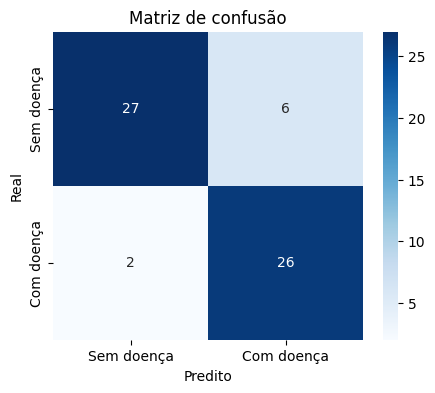

In [ ]:
y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

metricas = pd.DataFrame({
    "Metrica": ["Acurácia", "Precisão", "Recall", "F1-score", "AUC"],
    "Valor": [acc, prec, rec, f1, auc]
})
display(metricas)

print(classification_report(y_test, y_pred, target_names=["Sem doença","Com doença"], zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Sem doença","Com doença"],
            yticklabels=["Sem doença","Com doença"])
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de confusão")
plt.show()

## Curva ROC e AUC

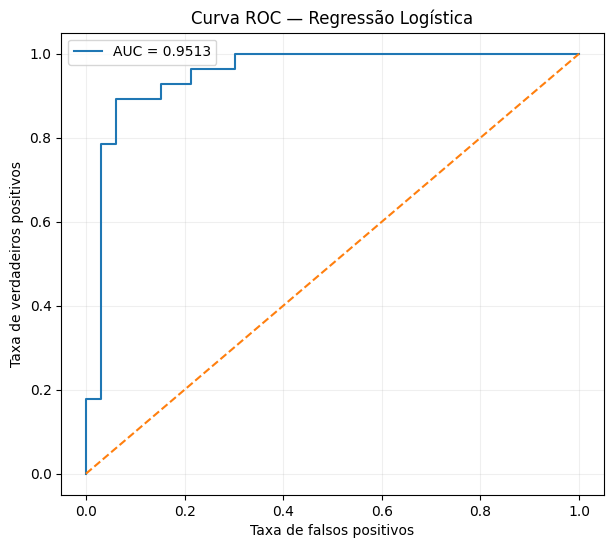

Acurácia: 0.8689
Precisão:  0.8125
Recall:    0.9286
F1-score:  0.8667
AUC:       0.9513
Iterações: 5


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0,1], [0,1], "--")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC — Regressão Logística")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Acurácia: {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"AUC:       {auc:.4f}")
print(f"Iterações: {modelo.n_iter_[0]}")